# Raid intensity

E14 found no measurable effect of a single raid within a year, but its episodes need 12
months without a raid before them. From 2023 IBAMA raids the same municipalities month
after month, so the sustained campaigns give few episodes. This notebook treats raid terms
as a continuous treatment (`output/research/mining_economics_leads.md`, E17).

- **Panel.** E14's sample municipalities (Legal Amazon, with a garimpo case in 2016–2025 or
  a raid) by month, from January 2019 until three months before SIVEP's last month.
- **Treatment.** log(1 + garimpo destruction and seizure terms), summed over windows of
  months relative to t: the next three months (a lead: do raids follow the outcome?), the
  month itself, and lags 1–3, 4–6 and 7–12. Three sources:
  - *own:* the municipality;
  - *border:* its bordering municipalities;
  - *ring:* the other municipalities whose centroid is within 150 km, for displacement
    beyond the next municipality.
- **Specification.** Municipality × calendar-month FE (local malaria seasons) and state ×
  month FE; Otto-3 clusters. The *year sum* adds the month and lag coefficients: the effect
  of a year of raiding. A pooled spec puts the month and the 12 before in one window,
  next to the lead, with the wild-cluster bootstrap.
- **Outcomes.** As in E14; garimpo against non-garimpo malaria in the same
  municipality-month is the main one, since raids follow local malaria.
- **Checks.** Without Roraima; from 2023 (the sustained campaigns); municipality and month
  FE only.

Code: `src/analysis/garimpo_intensity.py`. Tables go to `output/analysis/garimpo/raid_intensity/`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis.garimpo import intensity as I

warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", 400)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)
pd.set_option("display.float_format", lambda value: f"{value:.4g}")

OUT = PROJECT_ROOT / "output" / "analysis" / "garimpo" / "raid_intensity"
OUT.mkdir(parents=True, exist_ok=True)

panel, raids, adjacency, ring, basins = I.load_inputs()
data = I.build_panel(panel, raids, adjacency, ring, basins)
print(data["mun_id"].nunique(), "municipalities in", data[I.CLUSTER].nunique(), "basins,",
      data["month"].min().strftime("%Y-%m"), "to", data["month"].max().strftime("%Y-%m"))

INFO:src.data.sources.biomes.preprocess:Excluding 2 non-municipality GADM ADM2 polygon(s) (e.g. lagoons).


INFO:src.data.sources.biomes.preprocess:Excluding 2 non-municipality GADM ADM2 polygon(s) (e.g. lagoons).


267 municipalities in 95 basins, 2019-01 to 2026-01


## 1. How raids are spread

In [2]:
raided = data[data["own_now"] > 0]
year = data["month"].dt.year
display(pd.DataFrame({
    "raided municipality-months": raided.groupby(raided["month"].dt.year).size(),
    "raided municipalities": raided.groupby(raided["month"].dt.year)["mun_id"].nunique(),
    "raid terms": np.expm1(raided["own_now"]).groupby(raided["month"].dt.year).sum().round(),
    "share of months with a raid next door": (data["border_now"] > 0).groupby(year).mean().round(3),
    "share with a raid in the ring": (data["ring_now"] > 0).groupby(year).mean().round(3),
}).fillna(0))
months_per_municipality = raided.groupby("mun_id").size()
display(months_per_municipality.describe(percentiles=[0.5, 0.75, 0.9]).round(1))
display(pd.Series({k: len(v) for k, v in ring.items()}).describe().round(1).rename("ring size"))

,raided municipality-months,raided municipalities,raid terms,share of months with a raid next door,share with a raid in the ring
month,,,,,
2019,28,19,74,0.042,0.012
2020,45,29,129,0.07,0.008
2021,64,34,365,0.081,0.011
2022,79,37,264,0.103,0.023
2023,125,48,726,0.155,0.018
2024,117,46,1080,0.148,0.022
2025,134,60,993,0.171,0.038
2026,4,4,11,0.064,0.015


count    98
mean    6.1
std     7.5
min       1
50%       3
75%       8
90%      17
max      39
dtype: float64

count    772
mean    21.2
std     19.7
min        0
25%        4
50%       14
75%       38
max       76
Name: ring size, dtype: float64

**Reading the results.** Raids grow and concentrate: the campaigns of 2023–25 raid the
same municipalities month after month.
- *Raided municipality-months:* 28 (2019) to 125–134 a year in 2023–25, in 19 to 60
  municipalities; raid terms 74 (2019) to 1,080 (2024).
- *Repetition:* the 98 raided municipalities have a median of 3 raided months, the top
  tenth 17 or more, at most 39.
- *Exposure next door:* the share of municipality-months with a raid in a bordering
  municipality goes from 4% (2019) to 17% (2025); in the ring, 1–4%. The ring holds a
  median of 14 municipalities.


## 2. Distributed lags

estimate


window                          lead    now  lag1_3  lag4_6  lag7_12  year sum
outcome                source                                                 
log1p_garimpo          own     0.073  0.068   0.051    0.04   -0.009      0.15
                       border  0.009 -0.006  -0.009  -0.006   -0.005    -0.026
                       ring   -0.005  0.004   -0.01  -0.015   -0.032    -0.053
log1p_garimpo_local    own     0.045   0.04   0.033   0.007   -0.006     0.074
                       border  0.001 -0.007  -0.004  -0.004   -0.009    -0.024
                       ring    0.001   0.02   0.007   0.002   -0.012     0.017
log1p_garimpo_incoming own     0.063  0.054   0.033   0.041   -0.005     0.123
                       border  0.012 -0.007  -0.005  -0.008   -0.003    -0.023
                       ring        0 -0.003  -0.016  -0.028   -0.038    -0.085
log1p_other_malaria    own     0.046  0.031   0.057   0.048    0.054     0.189
                       border  0.018  0.031   0.021   0.024    0.004     0.079
                       ring   -0.007 -0.022  -0.015   0.002    0.021    -0.013
garimpo_vs_other       own     0.027  0.037  -0.006  -0.008   -0.063    -0.039
                       border -0.008 -0.037   -0.03   -0.03   -0.008    -0.105
                       ring    0.002  0.025   0.004  -0.017   -0.053     -0.04
incoming_vs_other      own     0.017  0.023  -0.023  -0.007   -0.059    -0.066
                       border -0.006 -0.037  -0.026  -0.032   -0.006    -0.102
                       ring    0.007  0.019  -0.001   -0.03   -0.059    -0.072

p


window                         lead   now  lag1_3  lag4_6  lag7_12  year sum
outcome                source                                               
log1p_garimpo          own    0.015 0.019   0.062   0.158    0.801     0.118
                       border 0.173 0.608   0.362   0.628    0.759     0.562
                       ring   0.867  0.92   0.738   0.495    0.206     0.599
log1p_garimpo_local    own    0.008  0.01   0.049   0.646    0.794     0.107
                       border 0.908 0.465   0.592   0.674    0.475     0.477
                       ring   0.957 0.549   0.771    0.93    0.481     0.847
log1p_garimpo_incoming own     0.03 0.043   0.193   0.092    0.883     0.186
                       border 0.035 0.503   0.563   0.366    0.828     0.532
                       ring   0.986 0.927   0.525   0.115    0.132     0.272
log1p_other_malaria    own    0.094 0.215   0.023   0.022    0.084     0.024
                       border 0.311 0.109   0.113   0.086    0.829     0.138
                       ring   0.777 0.207   0.521   0.912    0.382     0.829
garimpo_vs_other       own    0.316 0.066   0.838   0.763     0.24     0.706
                       border 0.567 0.027   0.006   0.027     0.53     0.015
                       ring   0.947 0.487   0.882   0.293     0.08     0.598
incoming_vs_other      own    0.546 0.248   0.362   0.779    0.274     0.525
                       border 0.722 0.038   0.032    0.01    0.636      0.02
                       ring   0.785 0.541   0.961   0.066     0.08     0.217

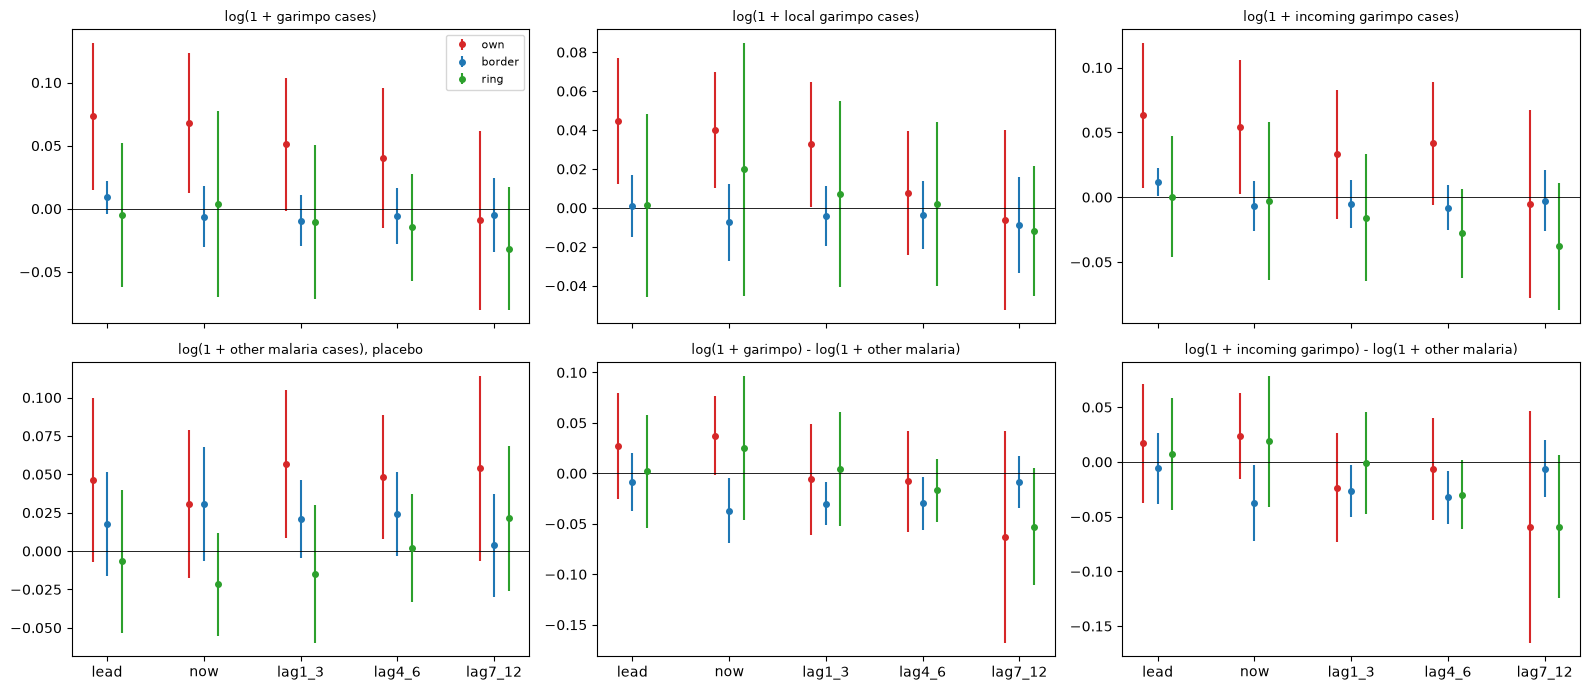

In [3]:
lags = pd.concat([I.distributed(data, outcome) for outcome in I.OUTCOMES], ignore_index=True)
lags.to_csv(OUT / "distributed.csv", index=False)
for value in ("estimate", "p"):
    print(value)
    display(lags.pivot_table(index=["outcome", "source"], columns="window", values=value, sort=False)
            [[*I.WINDOWS, "year sum"]].round(3))

order = list(I.WINDOWS)
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for ax, outcome in zip(axes.ravel(), I.OUTCOMES):
    for shift, (source, color) in zip((-0.15, 0, 0.15), zip(I.SOURCES, ("C3", "C0", "C2"))):
        part = lags[(lags.outcome == outcome) & (lags.source == source)].set_index("window").reindex(order)
        ax.errorbar(np.arange(len(order)) + shift, part.estimate, yerr=1.96 * part.se, fmt="o", ms=4, color=color,
                    label=source)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order)
    ax.set_title(I.OUTCOMES[outcome], fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Reading the results.** Raids go where garimpo malaria is rising, and a year of raiding
does not lower it at the site, next door or within 150 km.
- *At the raid, garimpo cases* rise before and with raids: the lead is +0.073 (p 0.015),
  the month +0.068 and lags 1–3 +0.051; the year sum is +0.15 (p 0.12), local and incoming
  alike. Other malaria also rises (year sum +0.19, p 0.024).
- *Against other malaria* at the raid: lead +0.03 (p 0.32), year sum −0.04 (p 0.71).
- *Next door:* garimpo cases do not move (year sum −0.03, p 0.56). Against other malaria
  the year sum is −0.105 (p 0.015), but this is other malaria rising next to raids
  (+0.08, p 0.14), not garimpo falling.
- *Ring (other municipalities within 150 km):* garimpo −0.05 (p 0.60); against other
  malaria −0.04 (p 0.60), with lags 7–12 at −0.05 (p 0.08).


## 3. Pooled windows and checks

In [4]:
roraima = data["mun_id"].str[:2].eq("14")
samples = {
    "baseline": (data, I.FE),
    "without Roraima": (data[~roraima], I.FE),
    "from 2023": (data[data["month"] >= "2023-01-01"], I.FE),
    "municipality and month FE": (data, "mun_id + t"),
}
POOLED_OUTCOMES = ["garimpo_vs_other", "incoming_vs_other", "log1p_garimpo", "log1p_other_malaria"]
pooled = pd.DataFrame([{"sample": name, **row} for name, (part, fe) in samples.items()
                       for outcome in POOLED_OUTCOMES for row in I.pooled(part, outcome, fe=fe)])
pooled.to_csv(OUT / "pooled.csv", index=False)
for value in ("estimate", "p", "p_wcb"):
    print(value)
    display(pooled.pivot_table(index=["sample", "source"], columns=["outcome", "window"], values=value,
                               sort=False).round(3))

sums = pd.concat([I.distributed(part, outcome, fe=fe).assign(sample=name)
                  for name, (part, fe) in samples.items() if name != "baseline" for outcome in POOLED_OUTCOMES],
                 ignore_index=True)
sums.to_csv(OUT / "distributed_checks.csv", index=False)
year_sums = sums[sums.window.isin(["lead", "year sum"])]
for value in ("estimate", "p"):
    print("lead and year sum,", value)
    display(year_sums.pivot_table(index=["sample", "source"], columns=["outcome", "window"], values=value,
                                  sort=False).round(3))

estimate


outcome                          garimpo_vs_other        incoming_vs_other        log1p_garimpo        log1p_other_malaria       
window                                       lead   past              lead   past          lead   past                lead   past
sample                    source                                                                                                 
baseline                  own                0.03 -0.051             0.017 -0.059         0.085  0.035               0.055  0.087
                          border           -0.016 -0.018            -0.014 -0.018         0.008 -0.004               0.024  0.014
                          ring              0.005  -0.04             0.008 -0.047        -0.004  -0.03              -0.008   0.01
without Roraima           own               0.033 -0.007              0.02 -0.011         0.061  0.048               0.028  0.055
                          border           -0.014 -0.013            -0.012 -0.012         0.007 -0.004               0.021  0.009
                          ring             -0.012 -0.031            -0.007 -0.031        -0.023 -0.031              -0.011      0
from 2023                 own               0.057  0.019             0.044  0.025         0.067  0.003                0.01 -0.016
                          border            0.013 -0.016             0.013 -0.014         0.004 -0.009              -0.009  0.007
                          ring              0.024 -0.021             0.017 -0.029         0.012 -0.018              -0.012  0.003
municipality and month FE own               0.041 -0.049             0.029 -0.051         0.085  0.025               0.044  0.074
                          border           -0.012 -0.022            -0.009 -0.015         0.008 -0.018               0.021  0.004
                          ring               0.05 -0.034             0.054 -0.034         0.011 -0.024              -0.039   0.01

p


outcome                          garimpo_vs_other       incoming_vs_other       log1p_garimpo       log1p_other_malaria      
window                                       lead  past              lead  past          lead  past                lead  past
sample                    source                                                                                             
baseline                  own               0.276 0.291             0.559 0.228         0.019 0.279               0.092 0.022
                          border            0.319 0.317             0.464 0.322         0.294 0.829               0.217   0.5
                          ring              0.884 0.077              0.78 0.045         0.918 0.316               0.749 0.671
without Roraima           own               0.281 0.859             0.548 0.738         0.078 0.183               0.345 0.069
                          border            0.421   0.5             0.534 0.509         0.379 0.838               0.309 0.673
                          ring              0.672 0.192             0.788 0.172         0.486 0.327               0.694  0.99
from 2023                 own               0.192 0.624             0.338 0.468         0.159  0.94               0.778 0.684
                          border             0.33 0.465             0.319 0.483         0.766  0.66               0.542 0.735
                          ring              0.559 0.311             0.654 0.164         0.756 0.405               0.663 0.884
municipality and month FE own               0.058 0.323             0.209 0.256         0.005 0.527                 0.1 0.013
                          border            0.519 0.168             0.679 0.423         0.248 0.292               0.322  0.87
                          ring              0.239 0.151             0.177 0.137         0.744 0.345               0.202 0.641

p_wcb


outcome                          garimpo_vs_other       incoming_vs_other       log1p_garimpo       log1p_other_malaria      
window                                       lead  past              lead  past          lead  past                lead  past
sample                    source                                                                                             
baseline                  own               0.342 0.363              0.59 0.321         0.049 0.321               0.158 0.029
                          border            0.364 0.323             0.546 0.327         0.294 0.831               0.251   0.5
                          ring              0.883 0.088             0.778 0.058         0.943 0.449               0.751  0.68
without Roraima           own               0.363 0.866             0.584 0.754         0.096 0.215               0.358 0.075
                          border             0.48 0.502             0.621 0.507          0.38  0.84               0.378 0.684
                          ring              0.676 0.202              0.79 0.171         0.536 0.478               0.699 0.989
from 2023                 own               0.297 0.641             0.413 0.485         0.217 0.946                0.79 0.702
                          border            0.333 0.472             0.315 0.485         0.767 0.707                0.55 0.734
                          ring              0.594 0.327             0.693 0.172          0.78 0.446               0.672 0.884
municipality and month FE own               0.099 0.424             0.255 0.371         0.009 0.565               0.174  0.04
                          border             0.59 0.191             0.765 0.461         0.258 0.331               0.412 0.868
                          ring              0.265 0.169             0.196  0.15         0.858 0.497               0.209 0.651

lead and year sum, estimate


outcome                          garimpo_vs_other          incoming_vs_other          log1p_garimpo          log1p_other_malaria         
window                                       lead year sum              lead year sum          lead year sum                lead year sum
sample                    source                                                                                                         
without Roraima           own               0.029     0.04             0.018    0.022         0.054    0.161               0.024    0.121
                          border           -0.007   -0.081            -0.006   -0.085         0.007   -0.007               0.015    0.075
                          ring             -0.013   -0.061            -0.008    -0.06        -0.021   -0.098              -0.007   -0.037
from 2023                 own               0.044    0.135             0.033    0.145         0.054    0.078                0.01   -0.058
                          border            0.015   -0.026             0.017   -0.019         0.005   -0.015              -0.011    0.011
                          ring              0.007    0.068             0.002    0.025         0.007    0.022              -0.001   -0.046
municipality and month FE own               0.041   -0.039             0.029   -0.052         0.078    0.129               0.038    0.168
                          border           -0.009   -0.085            -0.006   -0.069         0.008   -0.045               0.017     0.04
                          ring              0.048    -0.01             0.053   -0.023         0.009   -0.017              -0.039   -0.007

lead and year sum, p


outcome                          garimpo_vs_other          incoming_vs_other          log1p_garimpo          log1p_other_malaria         
window                                       lead year sum              lead year sum          lead year sum                lead year sum
sample                    source                                                                                                         
without Roraima           own               0.318    0.702             0.563     0.82         0.055    0.172               0.344    0.109
                          border            0.635     0.07             0.754    0.077         0.295    0.877               0.414    0.191
                          ring              0.616    0.406             0.734    0.359         0.497    0.357               0.779    0.645
from 2023                 own               0.259    0.279             0.426    0.233         0.178    0.554               0.771    0.524
                          border            0.265    0.576              0.23    0.646         0.713    0.731               0.469    0.757
                          ring              0.787    0.486             0.931    0.756         0.817      0.8               0.981    0.501
municipality and month FE own               0.067    0.702             0.211    0.589         0.006    0.207               0.109    0.028
                          border            0.623    0.028             0.769    0.137         0.216    0.323               0.384    0.503
                          ring               0.21    0.911             0.151    0.753         0.751    0.854               0.173     0.91

**Reading the results.** The nulls hold in the pooled spec and the checks, including the
sustained campaigns from 2023.
- *Pooled past year (the month and the 12 before), against other malaria:* own −0.051
  (Otto-3 p 0.29, bootstrap 0.36); border −0.018 (p 0.32); ring −0.040 (p 0.077,
  bootstrap 0.088), incoming −0.047 (p 0.045, bootstrap 0.058). The ring's garimpo cases
  themselves do not fall (−0.03, p 0.32).
- *Lead:* garimpo cases at the raid +0.085 (p 0.019, bootstrap 0.049). Raids are targeted
  at rising garimpo.
- *Without Roraima:* own past −0.007 (p 0.86); ring −0.031 (p 0.19); border year sum
  −0.08 (p 0.07), again with other malaria rising.
- *From 2023:* own past +0.019 (p 0.62), year sum +0.135 (p 0.28); border and ring within
  ±0.03. Sustained raiding does not reduce garimpo malaria where it happens or nearby.
- *Municipality and month FE:* the same pattern (own past −0.049, p 0.32).
